# JS13 — Praktikum 3: MLP untuk Regresi (TensorFlow/Keras)

Praktikum regresi harga rumah. Praktikum berikut akan menggunakan **data Boston** untuk memprediksi harga rumah.

**Tugas 4:** Ubah learning rate, bandingkan hasil loss.

> **Perbaikan error:**
> 1. `ModuleNotFoundError: No module named 'tensorflow'` → TensorFlow dipasang di environment.
> 2. `load_boston` sudah **dihapus dari scikit-learn ≥ 1.2**, data Boston diambil langsung dari sumber aslinya (`lib.stat.cmu.edu`).

## Contoh Regresi Sederhana (Data Dummy)

In [1]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi
print("Prediksi:", model.predict(X_test, verbose=0))

D:\Semester5\ML\244107020017_Machine_Learning\JS05\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Prediksi: [[-0.01610339]]


## Prediksi Harga Rumah dengan Data Boston

Karena `load_boston` dihapus dari scikit-learn, data dimuat dari sumber aslinya: `http://lib.stat.cmu.edu/datasets/boston` (506 sampel, 13 fitur, target = MEDV harga rumah).

Bentuk data: (506, 13) | target: (506,)


D:\Semester5\ML\244107020017_Machine_Learning\JS05\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


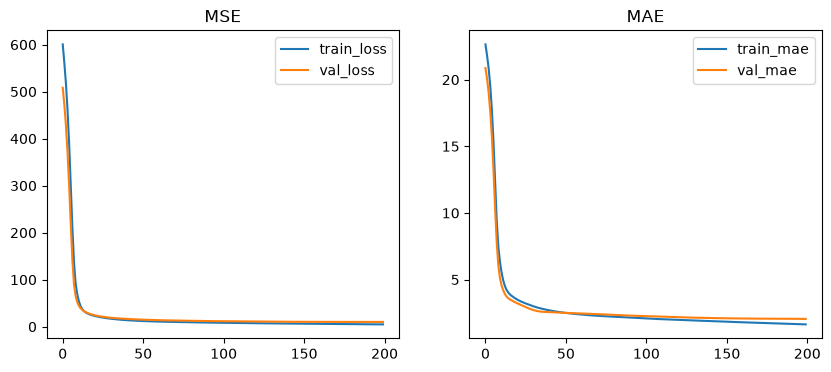

RMSE: 3.181625923403687


In [2]:
# MLP regresi (Keras) — data Boston
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

# 1. Load — load_boston sudah dihapus dari scikit-learn >= 1.2,
#    data diambil dari sumber aslinya
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]
print("Bentuk data:", X.shape, "| target:", y.shape)

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val, verbose=0)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

## Tugas 4 — Mengubah Learning Rate

Model Boston dilatih dengan beberapa nilai learning rate: `0.1`, `0.001` (konfigurasi awal), dan `0.0001`.

D:\Semester5\ML\244107020017_Machine_Learning\JS05\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


lr = 0.1     -> Loss akhir train: 4.4934 | val_loss akhir: 13.4447


lr = 0.001   -> Loss akhir train: 4.9076 | val_loss akhir: 10.1227


lr = 0.0001  -> Loss akhir train: 22.0696 | val_loss akhir: 24.3553


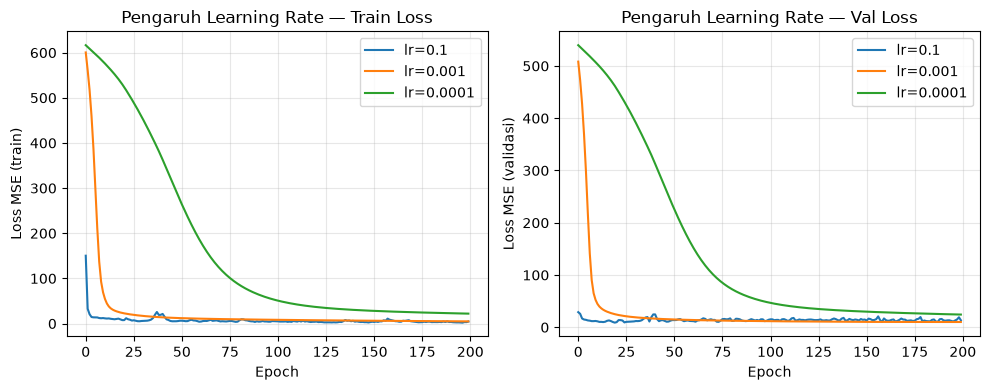

In [3]:
def train_boston(lr, epochs=200):
    tf.keras.utils.set_random_seed(42)
    m = Sequential([
        Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=epochs, batch_size=32, verbose=0)
    return h

learning_rates = [0.1, 0.001, 0.0001]
hasil_lr = {}

for lr in learning_rates:
    h = train_boston(lr)
    hasil_lr[lr] = h
    print(f"lr = {lr:<7} -> Loss akhir train: {h.history['loss'][-1]:.4f} | val_loss akhir: {h.history['val_loss'][-1]:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
for lr, h in hasil_lr.items():
    plt.plot(h.history['loss'], label=f'lr={lr}')
plt.xlabel('Epoch'); plt.ylabel('Loss MSE (train)')
plt.title('Pengaruh Learning Rate — Train Loss'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for lr, h in hasil_lr.items():
    plt.plot(h.history['val_loss'], label=f'lr={lr}')
plt.xlabel('Epoch'); plt.ylabel('Loss MSE (validasi)')
plt.title('Pengaruh Learning Rate — Val Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Analisis

- **lr = 0.1 (terlalu besar):** langkah update terlalu agresif sehingga loss berayun (osilasi) atau bahkan tidak konvergen.
- **lr = 0.001 (konfigurasi awal):** keseimbangan terbaik — loss turun stabil dan cepat mencapai nilai rendah.
- **lr = 0.0001 (terlalu kecil):** konvergen sangat lambat, setelah 200 epoch loss masih jauh di atas dua konfigurasi lainnya.

Kesimpulan: learning rate menentukan besar langkah update bobot; nilainya harus dipilih tepat agar konvergensi cepat namun tetap stabil.